# Лабораторная работа № 2. Визуализация данных
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение программных средств для визуализации наборов данных.

**Задачи:** настроить Matplotlib и Seaborn; изучить их основные типы графиков; научиться рассматривать данные по графикам.

**Данные:** Telecom Churn для учебного примера; RCAEval RE2-OB из лабораторной № 1 для индивидуального задания.

## 1. Локальный запуск проекта
Используем то же окружение Conda `rcaeval-ai`. В VS Code выбираем это ядро и нажимаем **Run All**.

Гистограмма показывает, какие значения встречаются чаще. Boxplot, или «ящик с усами», помогает сравнить середину и разброс значений. Countplot считает записи по категориям. Scatter и pairplot сравнивают пары показателей. Heatmap показывает силу их совместного изменения с помощью цвета.

Подключаем библиотеки.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

Задаём пути к данным и результатам.

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab02'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

Выводим версии Python и библиотек.

In [3]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'pyarrow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python        3.11.17
numpy           2.2.6
pandas          2.3.3
matplotlib     3.10.9
seaborn        0.13.2
pyarrow        21.0.0
Name: Версия, dtype: object

Определяем короткую функцию для сохранения и показа графиков.

In [3]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 2. Учебная задача: уход клиентов компании
Повторяем пример методички на `telecom_churn.csv`. Строка описывает одного клиента. В таблице есть штат, подключённые услуги, число и длительность звонков, начисления и метка ухода `Churn`. `False` означает, что клиент остался, `True` — что ушёл.

Файл взят из [репозитория учебного курса mlcourse.ai](https://github.com/Yorko/mlcourse.ai/blob/main/data/telecom_churn.csv). [Описание данных и визуализации](https://mlcourse.ai/book/topic02/topic02_visual_data_analysis.html). Это учебный набор из примера, а индивидуальный набор остаётся прежним RCAEval.

### 2.1. Загрузка и просмотр данных

Загружаем учебный файл, если локальной копии ещё нет.

In [4]:
TELECOM_DIR = ROOT / 'data/raw/telecom'
TELECOM_DIR.mkdir(parents=True, exist_ok=True)
telecom_path = TELECOM_DIR / 'telecom_churn.csv'
telecom_url = 'https://raw.githubusercontent.com/Yorko/mlcourse.ai/main/data/telecom_churn.csv'
if not telecom_path.is_file():
    with urlopen(telecom_url, timeout=45) as response:
        telecom_path.write_bytes(response.read())

Читаем датасет в таблицу pandas.

In [5]:
telecom = pd.read_csv(telecom_path)

Показываем первые строки и список столбцов.

In [6]:
display(telecom.head())
print('Размер таблицы:', telecom.shape)
print('Столбцы:', telecom.columns.tolist())

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


Размер таблицы: (3333, 20)
Столбцы: ['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']


Выводим типы столбцов и число пропусков.

In [7]:
telecom.info()
display(telecom.isna().sum().to_frame('Пропуски'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

,Пропуски
State,0
Account length,0
Area code,0
International plan,0
Voice mail plan,0
Number vmail messages,0
Total day minutes,0
Total day calls,0
Total day charge,0
Total eve minutes,0


В этой таблице числовой формат не всегда означает измерение. `Area code` - код телефонной зоны, поэтому его нельзя считать величиной нагрузки. `State`, названия тарифных опций и `Churn` - категории. Длительность звонков и начисления это числовые показатели.

### 2.2. Гистограммы и столбчатые графики
У гистограммы по горизонтали идут интервалы значений, по вертикали — количество клиентов. Столбцы по номерам строк показывают другой вид данных: один столбец относится к одному клиенту.

Строим гистограмму длительности дневных звонков.

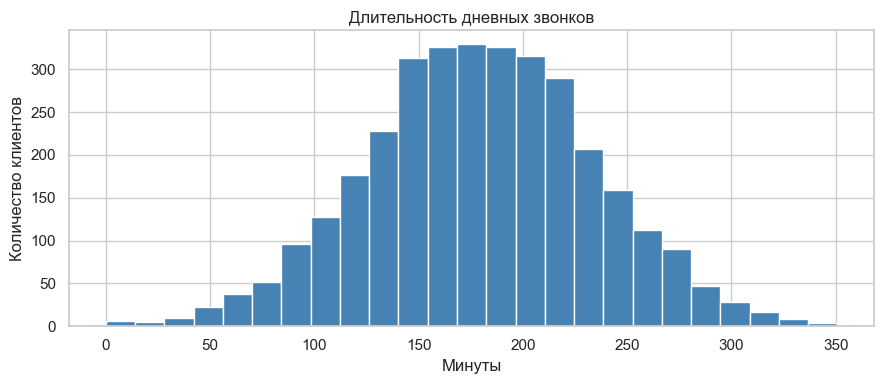

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
telecom['Total day minutes'].hist(bins=25, ax=ax, color='steelblue', edgecolor='white')
ax.set(title='Длительность дневных звонков', xlabel='Минуты', ylabel='Количество клиентов')
fig.tight_layout()
save_show(fig, '01_telecom_day_hist.png')

Большинство клиентов находится в середине диапазона, а очень короткие и очень длинные разговоры встречаются реже. Высота столбика показывает число клиентов, а не суммарное время их разговоров.

Строим общий обзор числовых столбцов, как на рис. 2.4.

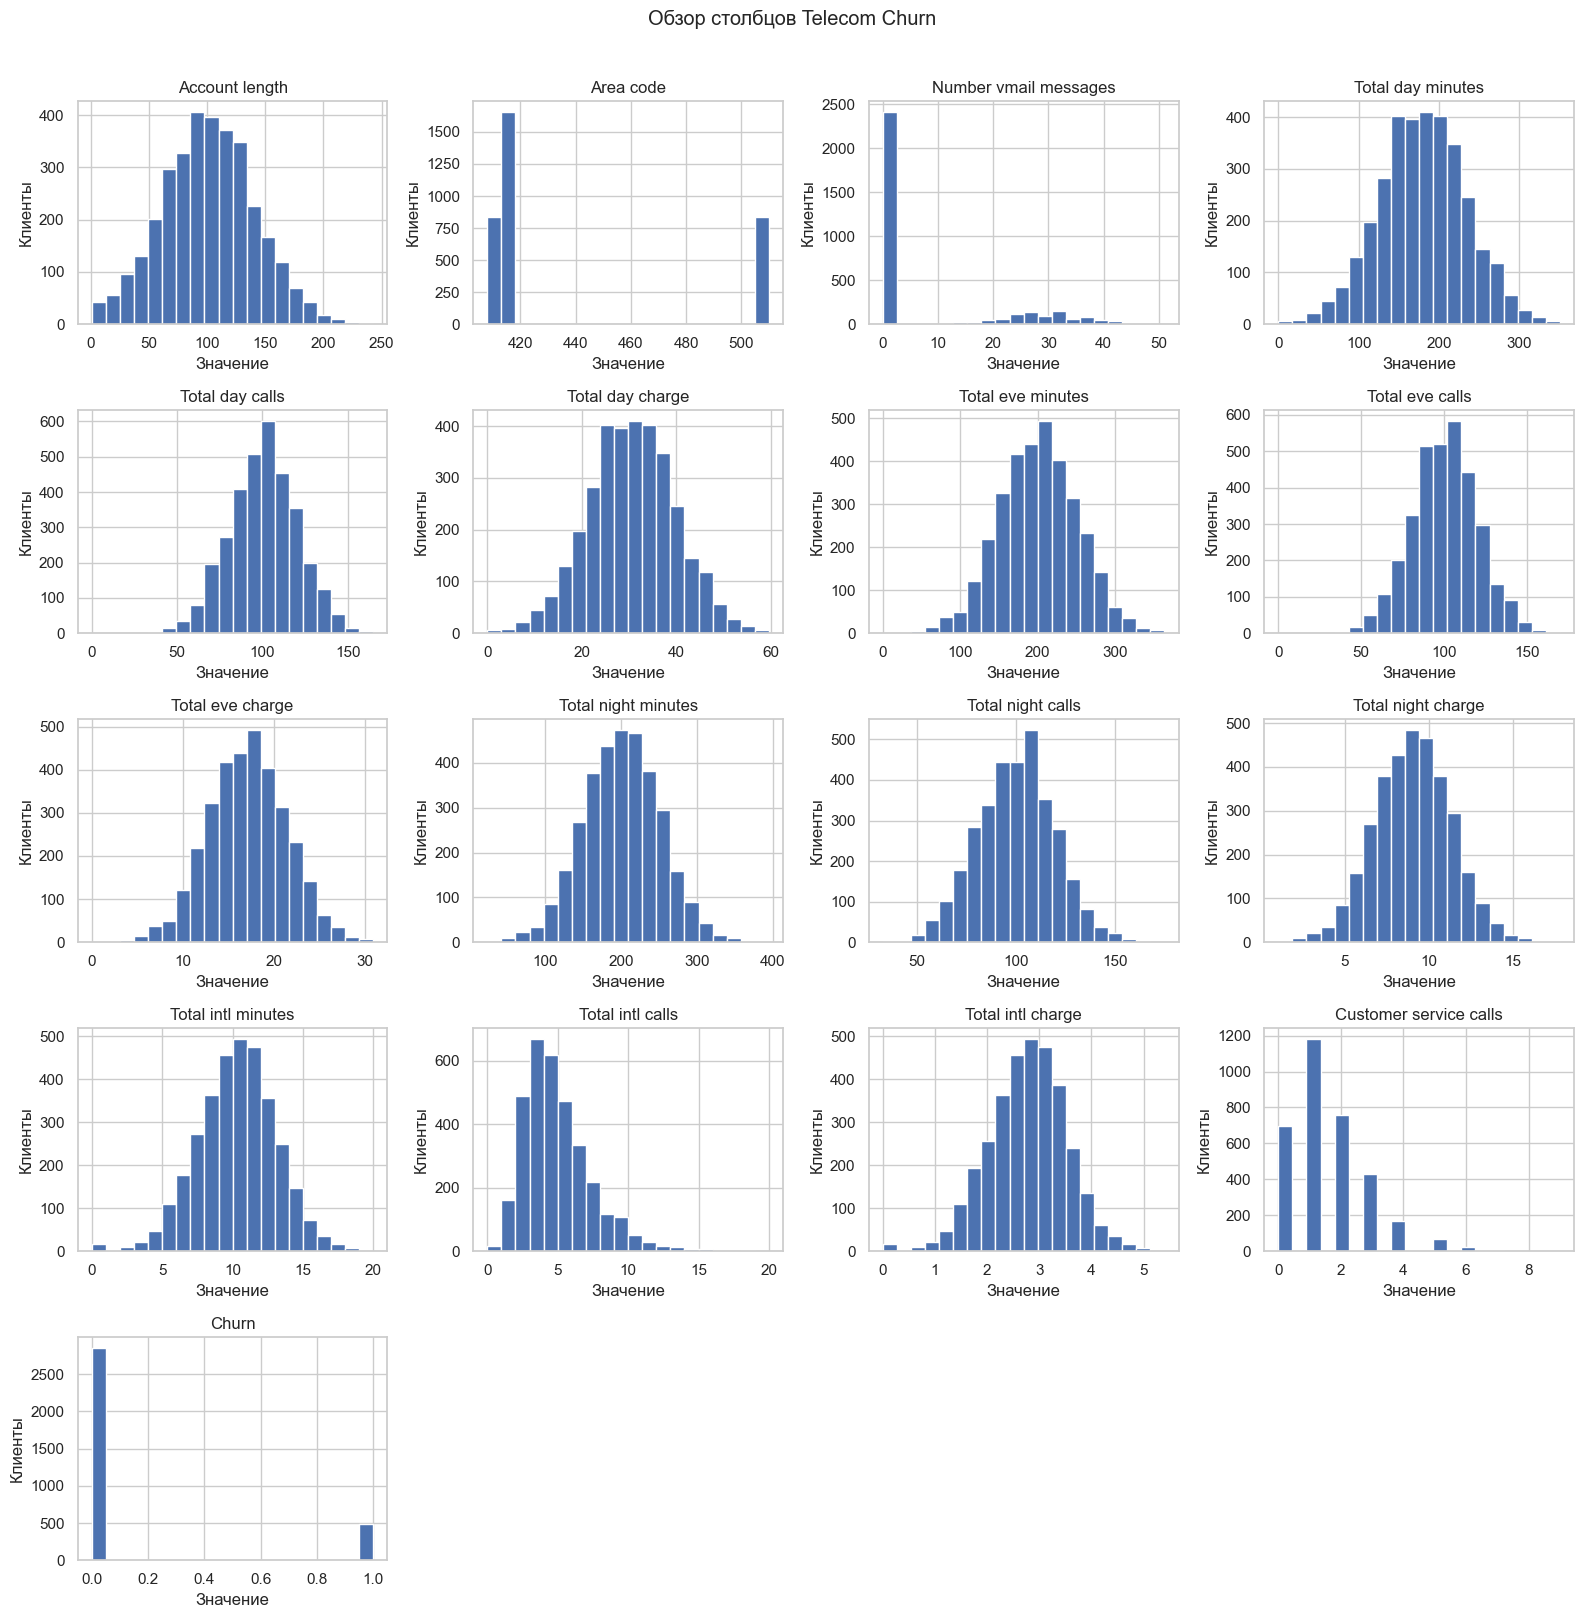

In [11]:
overview = telecom.select_dtypes(include=['number', 'bool']).astype(float)
axes = overview.hist(bins=20, figsize=(16, 16), layout=(5, 4), edgecolor='white')
for ax in axes.flat:
    if ax.get_visible():
        ax.set_xlabel('Значение')
        ax.set_ylabel('Клиенты')
fig = axes.flat[0].figure
fig.suptitle('Обзор столбцов Telecom Churn', y=1.01)
fig.tight_layout()
save_show(fig, '02_telecom_all_hist.png')

Этот обзор повторяет числовое представление из методички. Столбцы `Area code` и `Churn` здесь тоже видны, но остаются категориями. Ниже для категорий строим countplot. Разные масштабы на отдельных графиках не позволяют сравнивать их высоту как величину одного показателя.

Сравниваем значения по клиентам, частоты точных значений и обычную гистограмму.

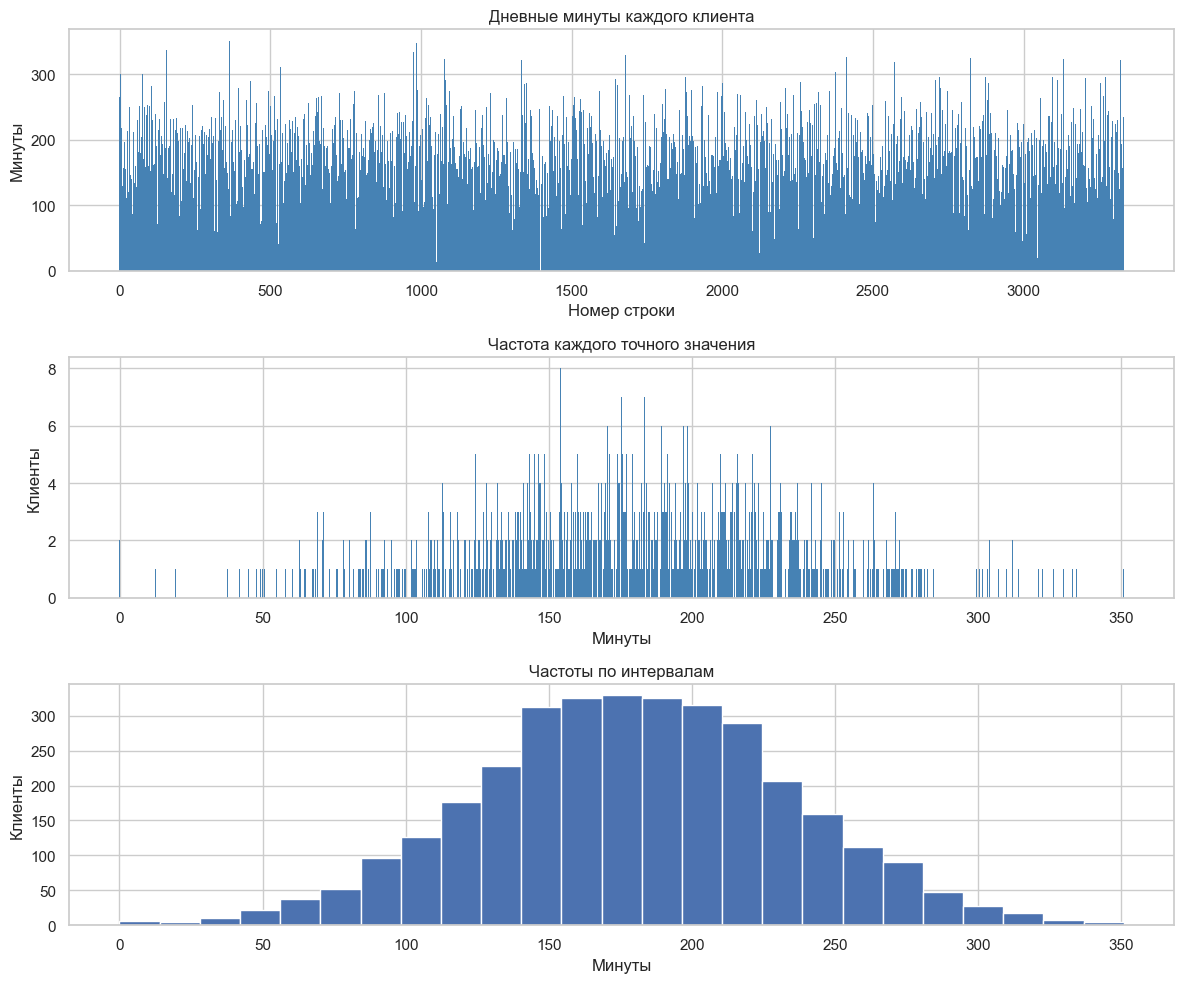

In [12]:
day = telecom['Total day minutes']
counts = day.value_counts().sort_index()
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].bar(telecom.index, day, width=1, color='steelblue', linewidth=0)
axes[0].set(title='Дневные минуты каждого клиента', xlabel='Номер строки', ylabel='Минуты')
axes[1].bar(counts.index, counts.values, width=0.1, color='steelblue', linewidth=0)
axes[1].set(title='Частота каждого точного значения', xlabel='Минуты', ylabel='Клиенты')
axes[2].hist(day, bins=25, edgecolor='white')
axes[2].set(title='Частоты по интервалам', xlabel='Минуты', ylabel='Клиенты')
fig.tight_layout()
save_show(fig, '03_telecom_bar_and_hist.png')

Первый график отвечает на вопрос, сколько говорил каждый клиент. Второй считает совпадающие значения. Третий объединяет близкие значения в интервалы, поэтому форму распределения на нём рассмотреть проще. График `bar` по номерам клиентов сам по себе не является гистограммой распределения.

### 2.3. Ящик с усами
Повторяем рис. 2.7–2.9. Линия внутри ящика — медиана, то есть середина упорядоченных значений. Ящик содержит среднюю половину значений. Усы показывают обычный разброс по правилу 1,5 межквартильного размаха; отдельные точки за усами требуют внимания, но не обязательно являются ошибками.

Строим boxplot дневных минут.

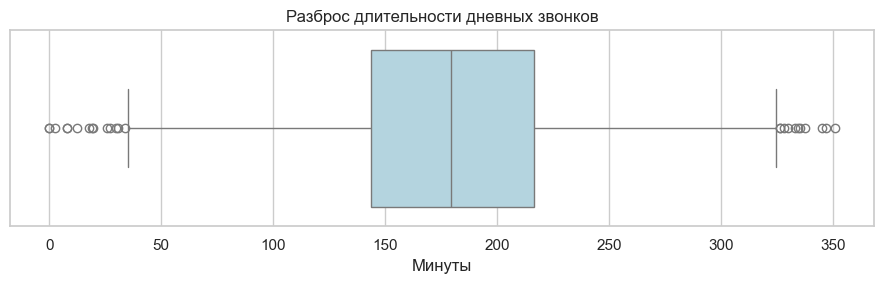

In [12]:
fig, ax = plt.subplots(figsize=(9, 3))
sns.boxplot(data=telecom, x='Total day minutes', ax=ax, color='lightblue')
ax.set(title='Разброс длительности дневных звонков', xlabel='Минуты')
fig.tight_layout()
save_show(fig, '04_telecom_boxplot.png')

Находим пять штатов с наибольшей суммой дневных минут.

In [13]:
top_day_states = telecom.groupby('State')['Total day minutes'].sum().nlargest(5)
display(top_day_states.to_frame('Сумма минут'))

,Сумма минут
State,
WV,18438.8
MN,15401.8
AL,14880.8
NY,14534.5
OH,14295.4


Сравниваем дневные минуты клиентов этих пяти штатов.

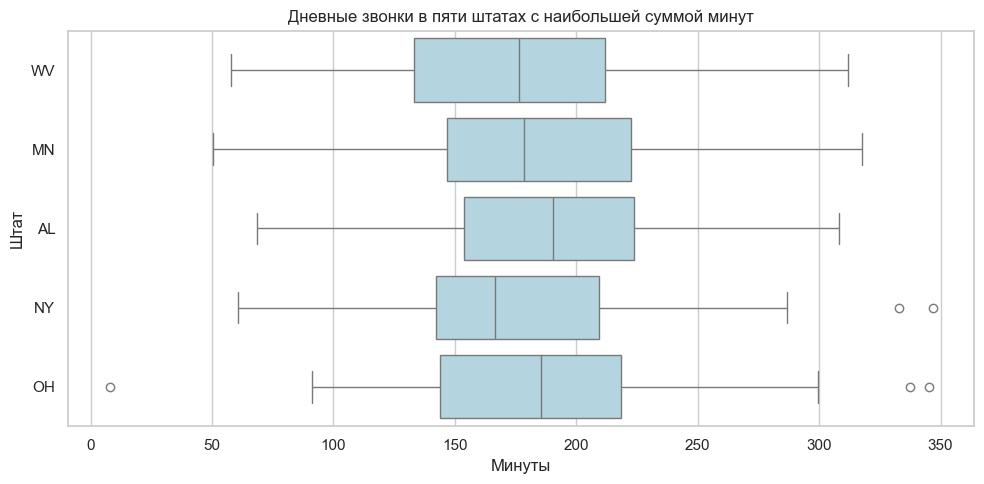

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=telecom[telecom['State'].isin(top_day_states.index)],
            x='Total day minutes', y='State', order=top_day_states.index,
            color='lightblue', ax=ax)
ax.set(title='Дневные звонки в пяти штатах с наибольшей суммой минут', xlabel='Минуты', ylabel='Штат')
fig.tight_layout()
save_show(fig, '05_telecom_state_boxplot.png')

Штаты выбраны по общей сумме минут, как в методичке. Большая сумма может получиться из-за большого числа клиентов, а не только из-за длинных разговоров каждого человека. Boxplot сравнивает уже сами значения клиентов: середину, разброс и отдельные крайние точки.

### 2.4. Категориальные признаки
Повторяем рис. 2.10. Countplot считает клиентов в каждой группе. Для штатов выбираем пять самых частых названий; это другой отбор, чем пять штатов по сумме минут.

Строим countplot ухода клиентов и пяти наиболее частых штатов.

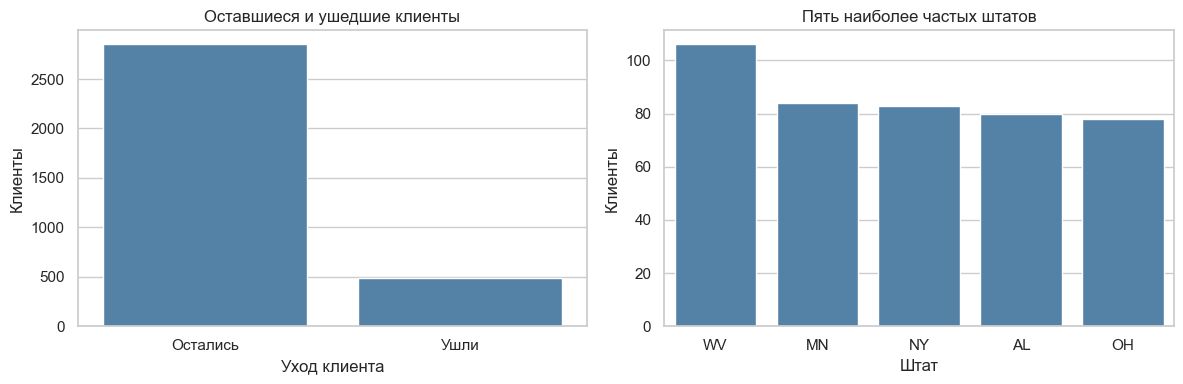

In [15]:
top_states = telecom['State'].value_counts().head(5).index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=telecom, x='Churn', order=[False, True], ax=axes[0], color='steelblue')
axes[0].set(title='Оставшиеся и ушедшие клиенты', xlabel='Уход клиента', ylabel='Клиенты')
axes[0].set_xticks([0, 1], ['Остались', 'Ушли'])
sns.countplot(data=telecom[telecom['State'].isin(top_states)], x='State', order=top_states,
              ax=axes[1], color='steelblue')
axes[1].set(title='Пять наиболее частых штатов', xlabel='Штат', ylabel='Клиенты')
fig.tight_layout()
save_show(fig, '06_telecom_countplot.png')

Считаем количество и долю ушедших клиентов.

In [16]:
churn_counts = telecom['Churn'].value_counts().sort_index()
display(churn_counts.to_frame('Клиенты'))
print(f'Доля ушедших: {telecom["Churn"].mean():.1%}')

Доля ушедших: 14.5%


,Клиенты
Churn,
False,2850
True,483


Столбец «Остались» заметно выше столбца «Ушли». В этом наборе группы имеют разный размер. Поэтому при сравнении цветных графиков важно отличать общее число точек от доли внутри группы.

### 2.5. Начисления и парные графики
Повторяем рис. 2.11–2.14. Отбираем столбцы с `charge` в названии. Это начисления за дневные, вечерние, ночные и международные услуги. Единицу валюты не придумываем: используем исходные значения.

Выбираем столбцы начислений.

In [17]:
charges = [name for name in telecom.columns if 'charge' in name]
print(charges)

['Total day charge', 'Total eve charge', 'Total night charge', 'Total intl charge']


Строим гистограммы начислений.

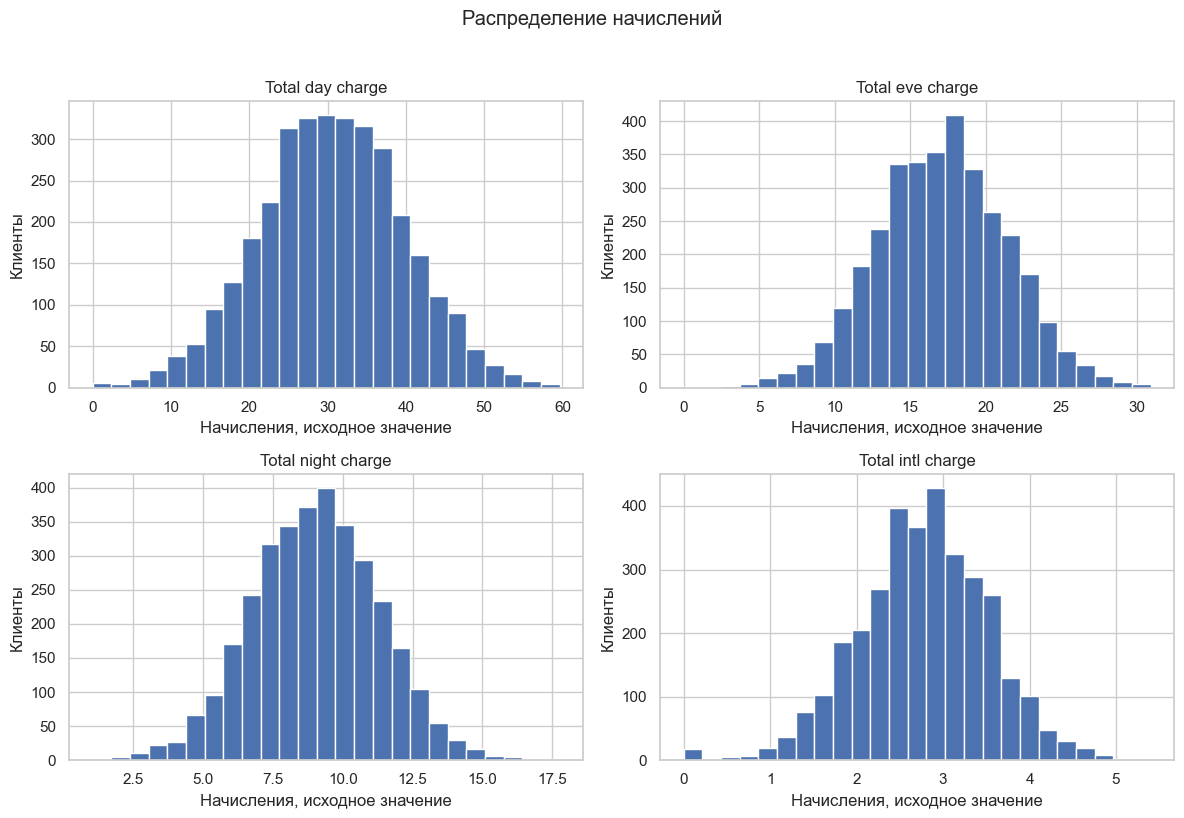

In [18]:
axes = telecom[charges].hist(bins=25, figsize=(12, 8), edgecolor='white')
for ax in axes.flat:
    ax.set_xlabel('Начисления, исходное значение')
    ax.set_ylabel('Клиенты')
fig = axes.flat[0].figure
fig.suptitle('Распределение начислений', y=1.02)
fig.tight_layout()
save_show(fig, '07_telecom_charge_hist.png')

Строим pairplot для всех пар начислений.

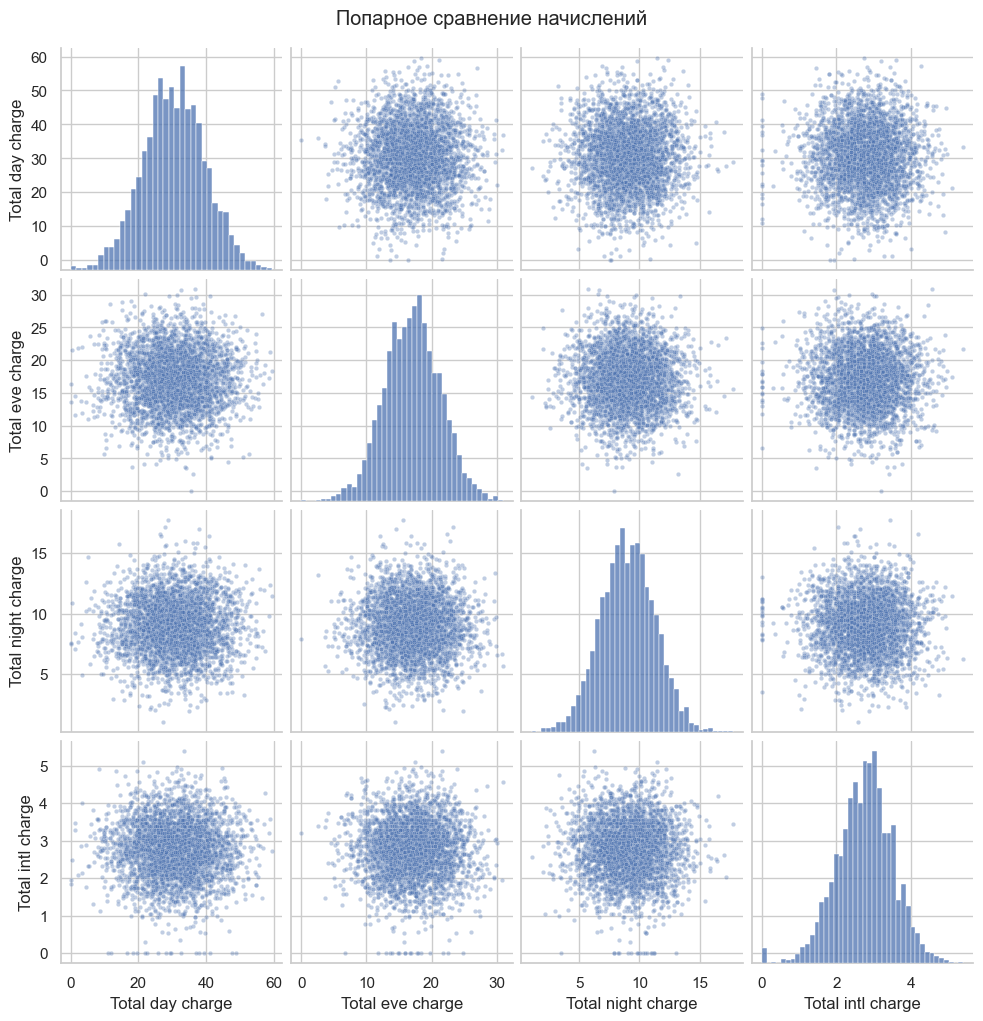

In [19]:
grid = sns.pairplot(telecom, vars=charges, diag_kind='hist', height=2.5,
                    plot_kws={'s': 10, 'alpha': 0.35})
grid.figure.suptitle('Попарное сравнение начислений', y=1.02)
save_show(grid.figure, '08_telecom_pairplot.png')

На диагонали показано распределение одного признака, в других клетках — пары. У каждой точки по горизонтали один вид начислений, по вертикали другой. Плотное облако без узкой наклонной линии означает, что по одной величине трудно точно угадать вторую.

Добавляем цвет по уходу клиента на парные графики.

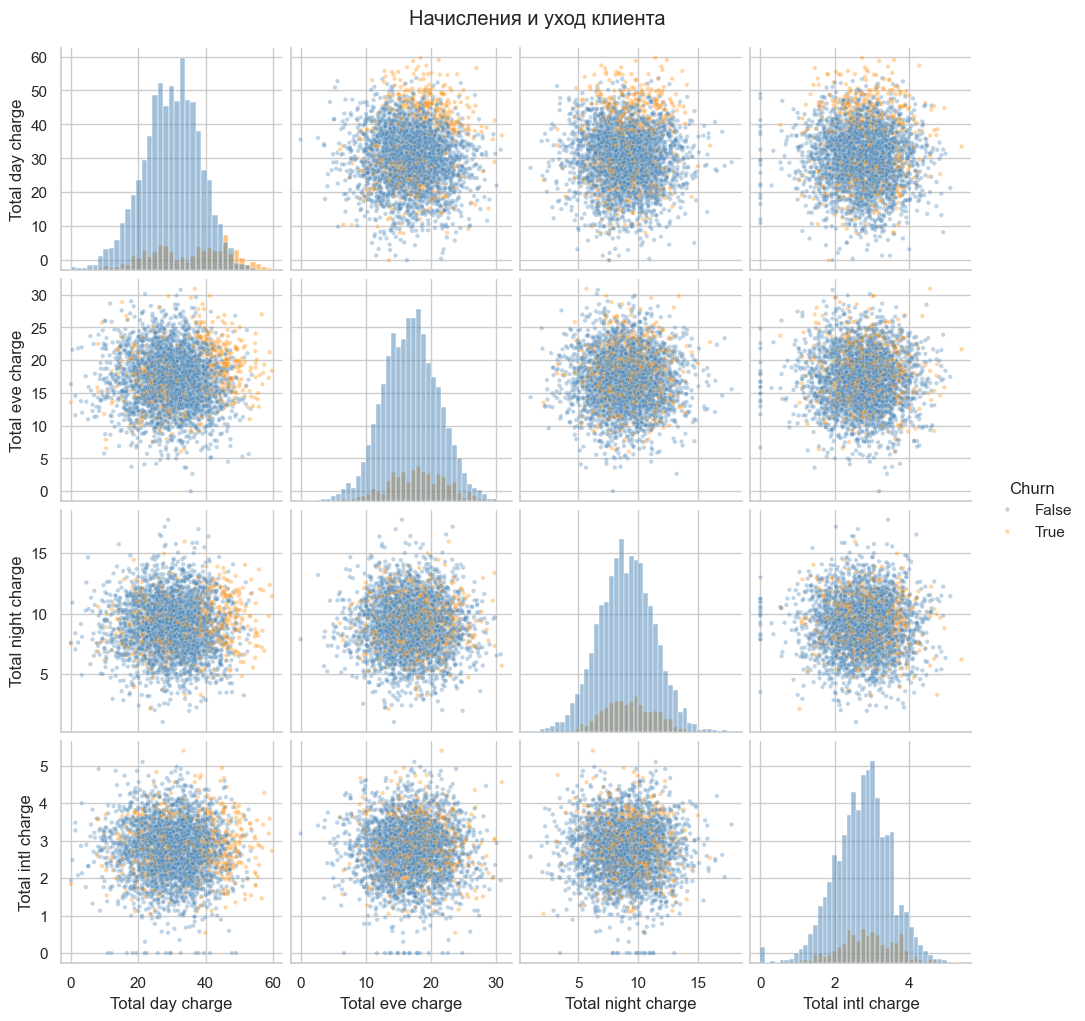

In [20]:
grid = sns.pairplot(telecom, vars=charges, hue='Churn', hue_order=[False, True],
                    palette={False: 'steelblue', True: 'darkorange'}, diag_kind='hist',
                    height=2.5, plot_kws={'s': 10, 'alpha': 0.35},
                    diag_kws={'common_norm': False})
grid.figure.suptitle('Начисления и уход клиента', y=1.02)
save_show(grid.figure, '09_telecom_pairplot_churn.png')

Цвет показывает известную метку `Churn`. Используем её для группировки, а не как дополнительное измерение величины начислений. На графиках группы частично перемешиваются, поэтому здесь нет простого визуального правила, которое точно определяет уход каждого клиента.

### 2.6. Настройка scatter
Одноцветный график, цвета и границы точек по категории, затем отдельный вывод групп с легендой.

Строим три варианта одной диаграммы рассеяния.

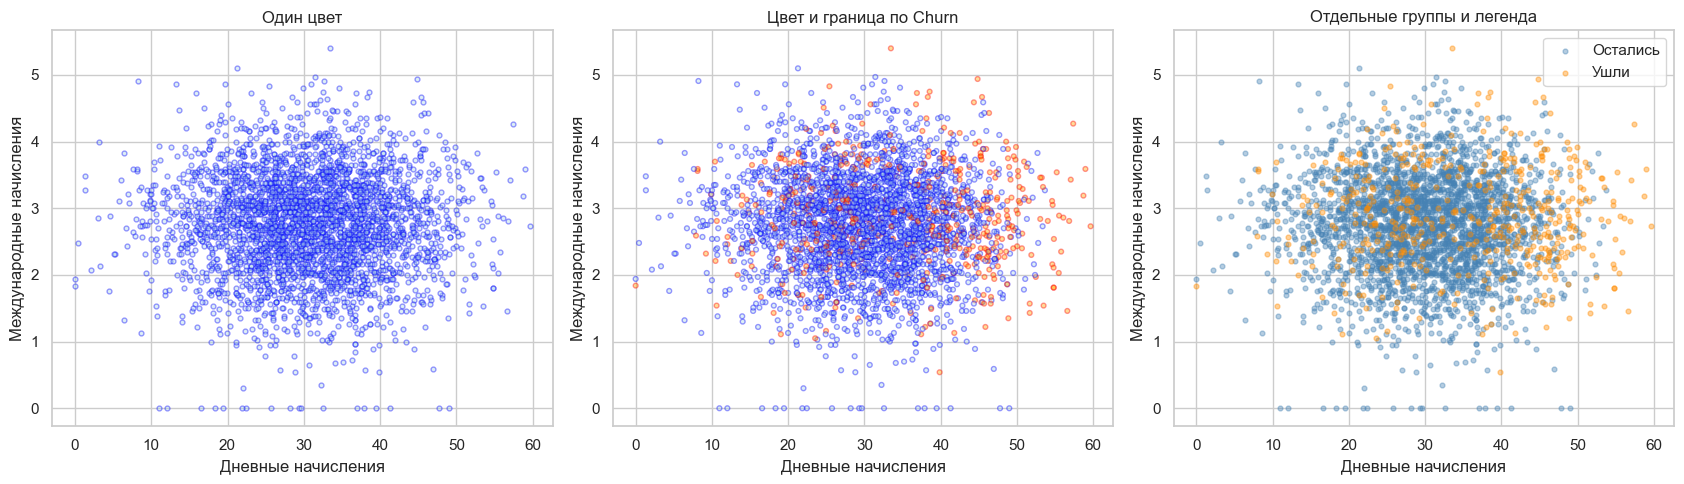

In [21]:
x, y = 'Total day charge', 'Total intl charge'
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(telecom[x], telecom[y], c='lightblue', edgecolors='blue', s=12, alpha=0.4)
axes[0].set_title('Один цвет')
axes[1].scatter(telecom[x], telecom[y], s=12, alpha=0.4,
                c=telecom['Churn'].map({False: 'lightblue', True: 'orange'}),
                edgecolors=telecom['Churn'].map({False: 'blue', True: 'red'}))
axes[1].set_title('Цвет и граница по Churn')
for value, label, color in [(False, 'Остались', 'steelblue'), (True, 'Ушли', 'darkorange')]:
    group = telecom[telecom['Churn'] == value]
    axes[2].scatter(group[x], group[y], label=label, color=color, s=12, alpha=0.4)
axes[2].set_title('Отдельные группы и легенда')
axes[2].legend()
for ax in axes:
    ax.set(xlabel='Дневные начисления', ylabel='Международные начисления')
fig.tight_layout()
save_show(fig, '10_telecom_scatter_styles.png')

Данные на всех трёх графиках одинаковые. Различаются только оформление и способ добавления групп. Легенда объясняет цвет, поэтому третий вариант легче читать.

### 2.7. Корреляция и тепловая карта
Корреляция близка к 1, когда два показателя обычно растут вместе, к −1 — когда один растёт, а другой уменьшается. Значение около нуля означает слабую линейную связь. Совместное изменение не доказывает влияние одного показателя на другой.

Рассчитываем корреляции числовых столбцов.

In [22]:
telecom_corr = telecom.corr(numeric_only=True)
display(telecom_corr.round(3))
telecom_corr.to_csv(REPORT / 'telecom_correlations.csv')

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
Account length,1.000,-0.012,-0.005,0.006,0.038,0.006,-0.007,0.019,-0.007,-0.009,-0.013,-0.009,0.010,0.021,0.010,-0.004,0.017
Area code,-0.012,1.000,-0.002,-0.008,-0.010,-0.008,0.004,-0.012,0.004,-0.006,0.017,-0.006,-0.018,-0.024,-0.018,0.028,0.006
Number vmail messages,-0.005,-0.002,1.000,0.001,-0.010,0.001,0.018,-0.006,0.018,0.008,0.007,0.008,0.003,0.014,0.003,-0.013,-0.090
Total day minutes,0.006,-0.008,0.001,1.000,0.007,1.000,0.007,0.016,0.007,0.004,0.023,0.004,-0.010,0.008,-0.010,-0.013,0.205
Total day calls,0.038,-0.010,-0.010,0.007,1.000,0.007,-0.021,0.006,-0.021,0.023,-0.020,0.023,0.022,0.005,0.022,-0.019,0.018
Total day charge,0.006,-0.008,0.001,1.000,0.007,1.000,0.007,0.016,0.007,0.004,0.023,0.004,-0.010,0.008,-0.010,-0.013,0.205
Total eve minutes,-0.007,0.004,0.018,0.007,-0.021,0.007,1.000,-0.011,1.000,-0.013,0.008,-0.013,-0.011,0.003,-0.011,-0.013,0.093
Total eve calls,0.019,-0.012,-0.006,0.016,0.006,0.016,-0.011,1.000,-0.011,-0.002,0.008,-0.002,0.009,0.017,0.009,0.002,0.009
Total eve charge,-0.007,0.004,0.018,0.007,-0.021,0.007,1.000,-0.011,1.000,-0.013,0.008,-0.013,-0.011,0.003,-0.011,-0.013,0.093
Total night minutes,-0.009,-0.006,0.008,0.004,0.023,0.004,-0.013,-0.002,-0.013,1.000,0.011,1.000,-0.015,-0.012,-0.015,-0.009,0.035


Строим тепловую карту корреляций.

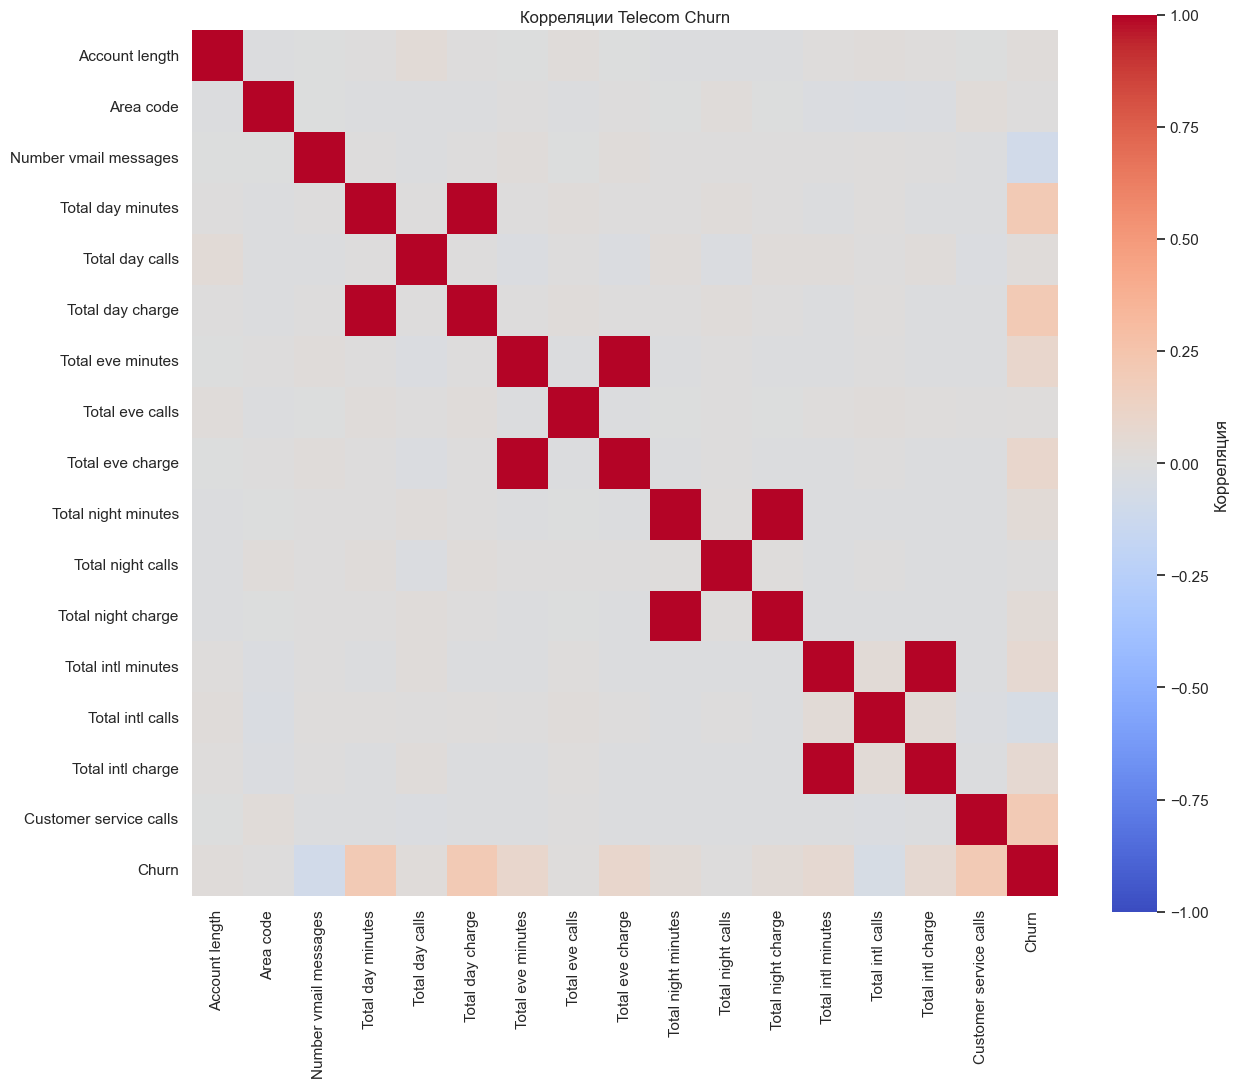

In [23]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(telecom_corr, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, ax=ax, cbar_kws={'label': 'Корреляция'})
ax.set_title('Корреляции Telecom Churn')
fig.tight_layout()
save_show(fig, '11_telecom_heatmap.png')

Показываем почти совпадающие по изменению пары.

In [24]:
upper = telecom_corr.where(np.triu(np.ones(telecom_corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().rename('Корреляция')
display(strong_pairs[strong_pairs.abs() > 0.95].sort_values(ascending=False).to_frame())

,,Корреляция
Total day minutes,Total day charge,1.000000
Total eve minutes,Total eve charge,1.000000
Total night minutes,Total night charge,0.999999
Total intl minutes,Total intl charge,0.999993


Полная карта повторяет методичку, поэтому включает и код зоны `Area code`, и метку `Churn`. Их числовой формат не делает их измерениями нагрузки. Почти одинаково меняются минуты разговоров и начисления за тот же период: это объяснимо расчётом стоимости по времени. Такие признаки могли бы дублировать информацию для будущей модели, но в этой работе столбцы не удаляем.

Формулируем краткий результат учебного примера.

In [25]:
display(Markdown(
    f'Изучен учебный набор: **{len(telecom)}** клиентов и **{telecom.shape[1]}** столбцов. '
    f'Пропущенных значений: **{int(telecom.isna().sum().sum())}**. '
    f'Остались **{int((~telecom["Churn"]).sum())}** клиентов, '
    f'ушли **{int(telecom["Churn"].sum())}**. '
    'Построены гистограммы, столбчатые графики, boxplot, countplot, pairplot, scatter и heatmap. '
    'Разобрались, как выбор графика помогает увидеть разные стороны одних данных.'))

Изучен учебный набор: **3333** клиентов и **20** столбцов. Пропущенных значений: **0**. Остались **2850** клиентов, ушли **483**. Построены гистограммы, столбчатые графики, boxplot, countplot, pairplot, scatter и heatmap. Разобрались, как выбор графика помогает увидеть разные стороны одних данных.

## 3. Индивидуальное задание: RCAEval из первой работы
### 3.1. Данные и выбранный пример
Используем прежние метрики RE2-OB. Это измерения работы сервисов демонстрационного интернет-магазина. Строка объединяет показатели сервисов в один момент времени. 

Идентификатор сценария читаем из результата первой работы. Метрики и время внесения сбоя берём из `data/raw/rcaeval/`. RCAEval повторно не скачиваем.

Методичка допускает набор по теме магистерской работы. Согласование с преподавателем и отсутствие совпадения с другими студентами подтверждаются студентом отдельно.

### 3.2. Чтение локальных файлов

Читаем сохранённый выбор сценария.

In [26]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
service = selection['root_cause_service']
case_dir = ROOT / 'data/raw/rcaeval' / case
print('Сценарий:', case)
print('Сервис:', service, 'Тип сбоя:', selection['fault'])

Сценарий: re2ob_checkoutservice_cpu_1
Сервис: checkoutservice Тип сбоя: cpu


Читаем метрики и время внедрения сбоя без скачивания.

In [27]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = pd.to_datetime(float(inject_path.read_text()), unit='s', utc=True)
timestamps = pd.to_datetime(df['time'], unit='s', utc=True)

Показываем первые строки и проверяем структуру данных.

In [28]:
display(df.head())
print('Размер таблицы:', df.shape)
print('Метрик без time:', df.shape[1] - 1)
print('Период UTC:', timestamps.min(), '—', timestamps.max())
print('Внедрение сбоя:', inject_time)
print('Всего пропусков:', int(df.isna().sum().sum()))

Размер таблицы: (1441, 73)
Метрик без time: 72
Период UTC: 2024-01-15 21:24:06+00:00 — 2024-01-15 21:48:06+00:00
Внедрение сбоя: 2024-01-15 21:36:06+00:00
Всего пропусков: 4


,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,redis_cpu,shippingservice_cpu,adservice_mem,cartservice_mem,checkoutservice_mem,currencyservice_mem,emailservice_mem,frontend_mem,paymentservice_mem,productcatalogservice_mem,recommendationservice_mem,redis_mem,shippingservice_mem,adservice_diskio,emailservice_diskio,recommendationservice_diskio,redis_diskio,adservice_socket,cartservice_socket,checkoutservice_socket,currencyservice_socket,emailservice_socket,frontend_socket,paymentservice_socket,productcatalogservice_socket,recommendationservice_socket,redis_socket,shippingservice_socket,adservice_workload,cartservice_workload,checkoutservice_workload,currencyservice_workload,emailservice_workload,frontend_workload,frontend-external_workload,paymentservice_workload,productcatalogservice_workload,recommendationservice_workload,shippingservice_workload,currencyservice_error,frontend_error,frontend-external_error,productcatalogservice_error,adservice_latency-50,cartservice_latency-50,checkoutservice_latency-50,currencyservice_latency-50,emailservice_latency-50,frontend_latency-50,paymentservice_latency-50,productcatalogservice_latency-50,recommendationservice_latency-50,shippingservice_latency-50,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,0.281538,0.144406,111521792.0,43528192.0,11702272.0,40288256.0,43175936.0,16592896.0,38535168.0,10289152.0,45064192.0,3014656.0,8818688.0,75387.659320,0.0,0.0,41276.452805,4.0,4.0,9.0,4.0,3.0,30.0,3.0,4.0,4.0,4.0,3.0,14.000,26.467,0.8,90.4,1.133,14.133,13.4,0.933,143.000,18.200,7.867,0.0,0.133,0.2,0.0,0.002971,0.003218,0.243182,0.066209,0.003,0.201323,0.004833,0.002032,0.007496,0.002753,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,0.281538,0.141128,111521792.0,43528192.0,11706368.0,40288256.0,43175936.0,16592896.0,38535168.0,10289152.0,45064192.0,3014656.0,8818688.0,75387.659320,0.0,0.0,41276.452805,4.0,4.0,9.0,4.0,3.0,30.0,3.0,4.0,4.0,4.0,3.0,14.267,25.133,1.0,82.8,1.133,14.133,12.0,0.933,142.333,18.133,7.333,0.0,0.133,0.0,0.0,0.002969,0.003270,0.299999,0.066256,0.003,0.206971,0.004833,0.002057,0.007500,0.002757,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,0.281538,0.137850,111521792.0,43528192.0,11706368.0,40288256.0,43175936.0,16592896.0,38535168.0,10289152.0,45064192.0,3014656.0,8818688.0,64127.674760,0.0,0.0,41276.452805,4.0,4.0,9.0,4.0,3.0,30.0,3.0,4.0,4.0,4.0,3.0,14.267,25.133,1.0,82.8,1.133,14.133,12.0,1.133,142.333,18.133,7.333,0.0,0.133,0.0,0.0,0.002969,0.003270,0.299999,0.066256,0.003,0.206971,0.004158,0.002057,0.007500,0.002757,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,0.281538,0.134571,111521792.0,43528192.0,11706368.0,40103936.0,43175936.0,16592896.0,38535168.0,10522624.0,45064192.0,3014656.0,8818688.0,46705.228361,0.0,0.0,41276.452805,4.0,4.0,9.0,4.0,3.0,30.0,3.0,4.0,4.0,4.0,3.0,14.267,25.133,1.0,82.8,1.133,11.867,12.0,1.133,141.867,18.133,7.333,0.0,0.000,0.0,0.0,0.002969,0.003270,0.299999,0.066256,0.003,0.209109,0.004158,0.002023,0.007500,0.002757,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,0.281538,0.131293,

Выбираем те же четыре показателя сервиса и добавляем метку периода в копию.

In [29]:
metrics = [f'{service}_{suffix}' for suffix in ['cpu', 'mem', 'latency-50', 'socket']]
metric_labels = dict(zip(metrics, ['CPU', 'Память', 'Задержка latency-50', 'Socket']))
period_order = ['До внедрения', 'Начиная с внедрения']
colors = {period_order[0]: 'steelblue', period_order[1]: 'darkorange'}
plot_data = df[metrics].replace([np.inf, -np.inf], np.nan).copy()
plot_data['Время'] = timestamps
plot_data['Период'] = np.where(timestamps < inject_time, period_order[0], period_order[1])
display(pd.DataFrame({'Метрика': metrics, 'Показатель': metric_labels.values(),
                      'Тип хранения': df[metrics].dtypes.astype(str).values}))

,Метрика,Показатель,Тип хранения
0,checkoutservice_cpu,CPU,float64
1,checkoutservice_mem,Память,float64
2,checkoutservice_latency-50,Задержка latency-50,float64
3,checkoutservice_socket,Socket,float64


`time` не считаем показателем производительности. Единицы CPU, памяти, задержки и socket не уточнены, поэтому графики используют исходные значения. `Период` — новая подпись для сравнения известных моментов времени. Она не означает автоматически найденную неисправность и не является исходной метрикой.

Считаем количество измерений в каждом периоде и средние значения.

In [30]:
period_counts = plot_data['Период'].value_counts().reindex(period_order)
period_means = plot_data.groupby('Период')[metrics].mean().reindex(period_order)
display(period_counts.to_frame('Измерения'))
display(period_means.rename(columns=metric_labels))
period_means.to_csv(REPORT / 'rcaeval_period_means.csv')

,Измерения
Период,
До внедрения,720
Начиная с внедрения,721


,CPU,Память,Задержка latency-50,Socket
Период,,,,
До внедрения,0.428854,1.172318e+07,0.296768,9.000000
Начиная с внедрения,18.290239,1.623859e+07,0.313606,10.961165


### 3.3. Временные графики
По горизонтали идёт время UTC, по вертикали — значение показателя. Пунктирная линия показывает известный момент внедрения сбоя. Для каждой метрики используем свой масштаб.

Строим временные ряды четырёх показателей.

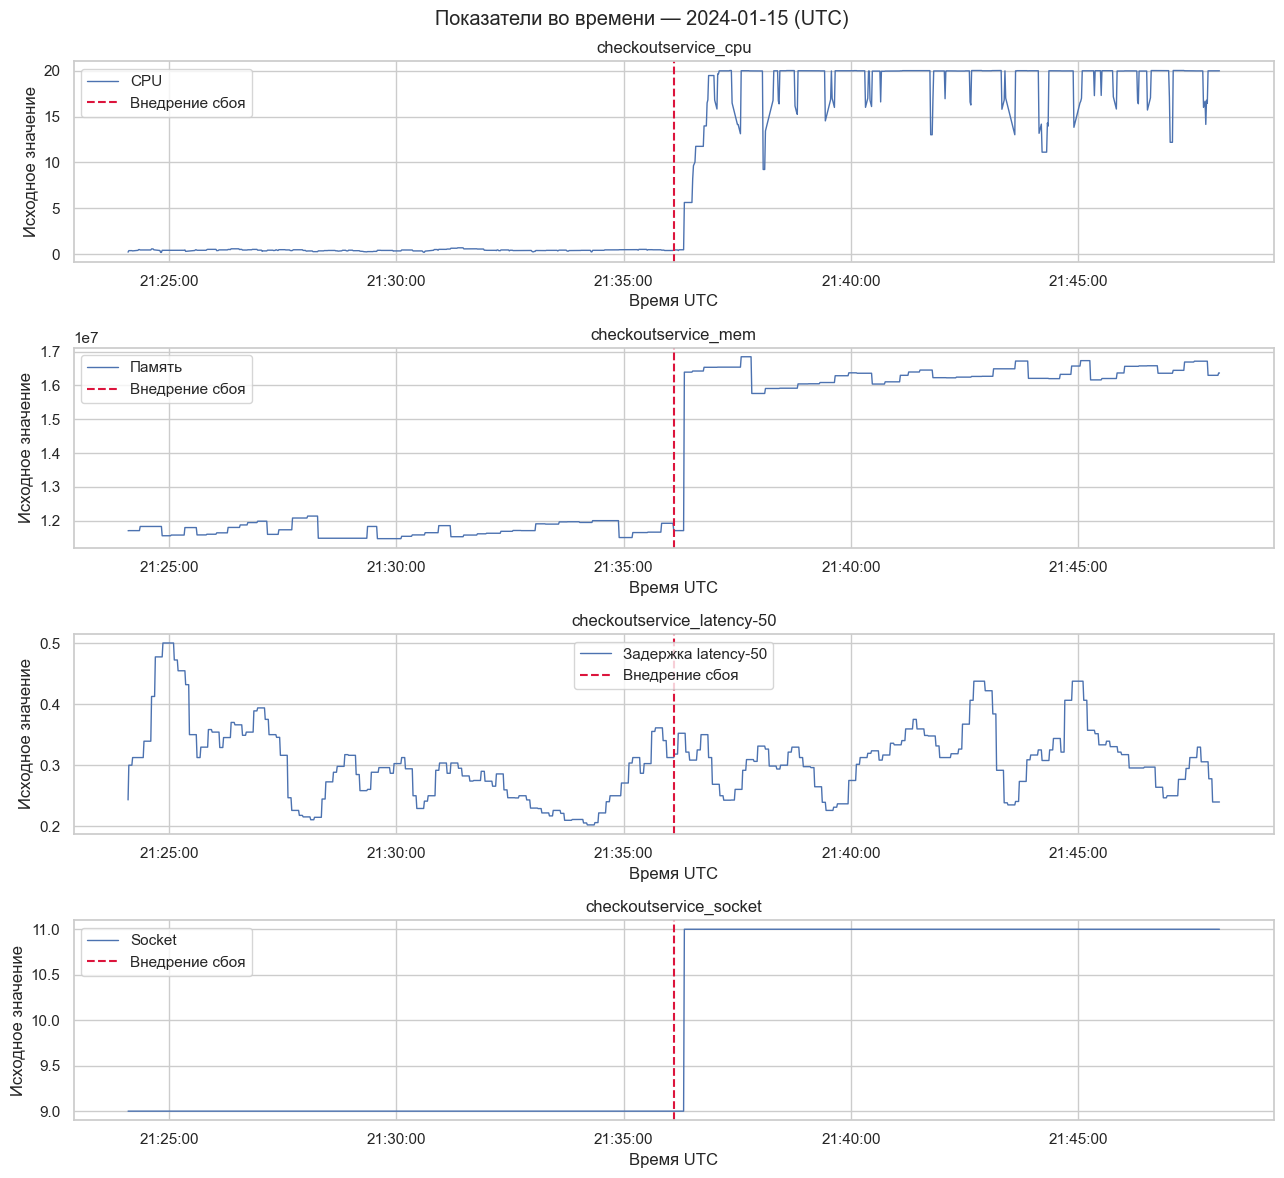

In [31]:
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for ax, metric in zip(axes, metrics):
    ax.plot(plot_data['Время'], plot_data[metric], linewidth=1, label=metric_labels[metric])
    ax.axvline(inject_time, color='crimson', linestyle='--', label='Внедрение сбоя')
    ax.set(title=metric, xlabel='Время UTC', ylabel='Исходное значение')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    ax.legend()
fig.suptitle(f'Показатели во времени — {timestamps.min().date()} (UTC)')
fig.tight_layout()
save_show(fig, '12_rcaeval_time.png')

На этом примере после отметки внедрения CPU, память и socket переходят к более высоким значениям. Задержка колеблется в обоих периодах; её большой пик был ещё до сбоя. Поэтому не любой заметный пик связан с внесённой неисправностью.

### 3.4. Гистограммы по периодам
Разделяем значения по цвету, чтобы понять, какие части распределения относятся к каждому периоду. Интервалы общие для обеих групп. Высота показывает число измерений; размеры групп выводились выше.

Сравниваем гистограммы до и после внедрения.

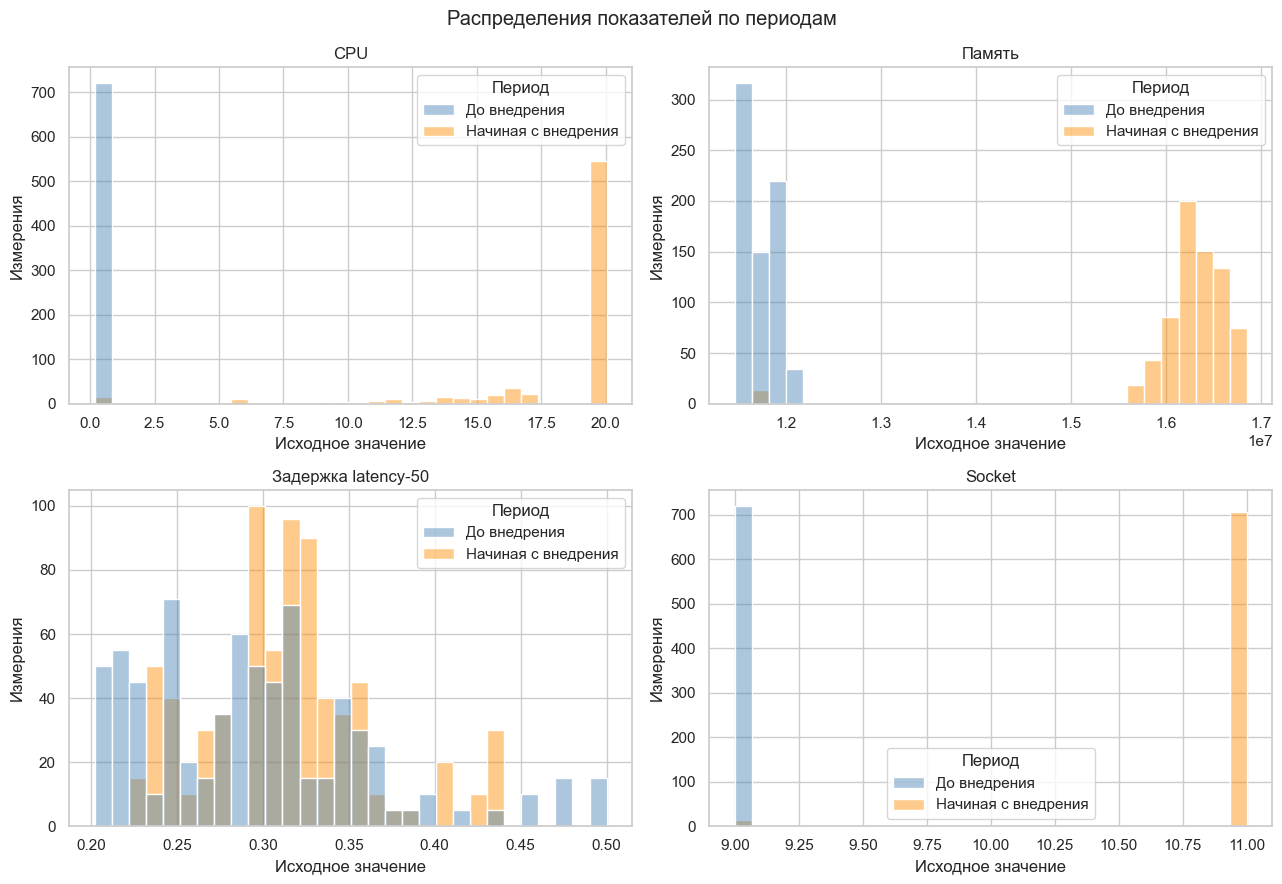

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, metrics):
    sns.histplot(data=plot_data, x=metric, hue='Период', hue_order=period_order,
                 palette=colors, bins=30, common_bins=True, alpha=0.45, ax=ax)
    ax.set(title=metric_labels[metric], xlabel='Исходное значение', ylabel='Измерения')
fig.suptitle('Распределения показателей по периодам')
fig.tight_layout()
save_show(fig, '13_rcaeval_hist.png')

У CPU и памяти два периода находятся в разных частях диапазона. У задержки группы сильнее перекрываются. Для socket видны значения около 9 и 11. Гистограмма показывает частоты, но не последовательность изменений во времени.

### 3.5. Boxplot по периодам
Сравниваем середину и разброс каждой группы. Точки за усами отмечены по общему правилу boxplot. Для показателя с почти одинаковыми значениями ящик может выглядеть как тонкая линия.

Строим отдельные ящики с усами для каждого периода.

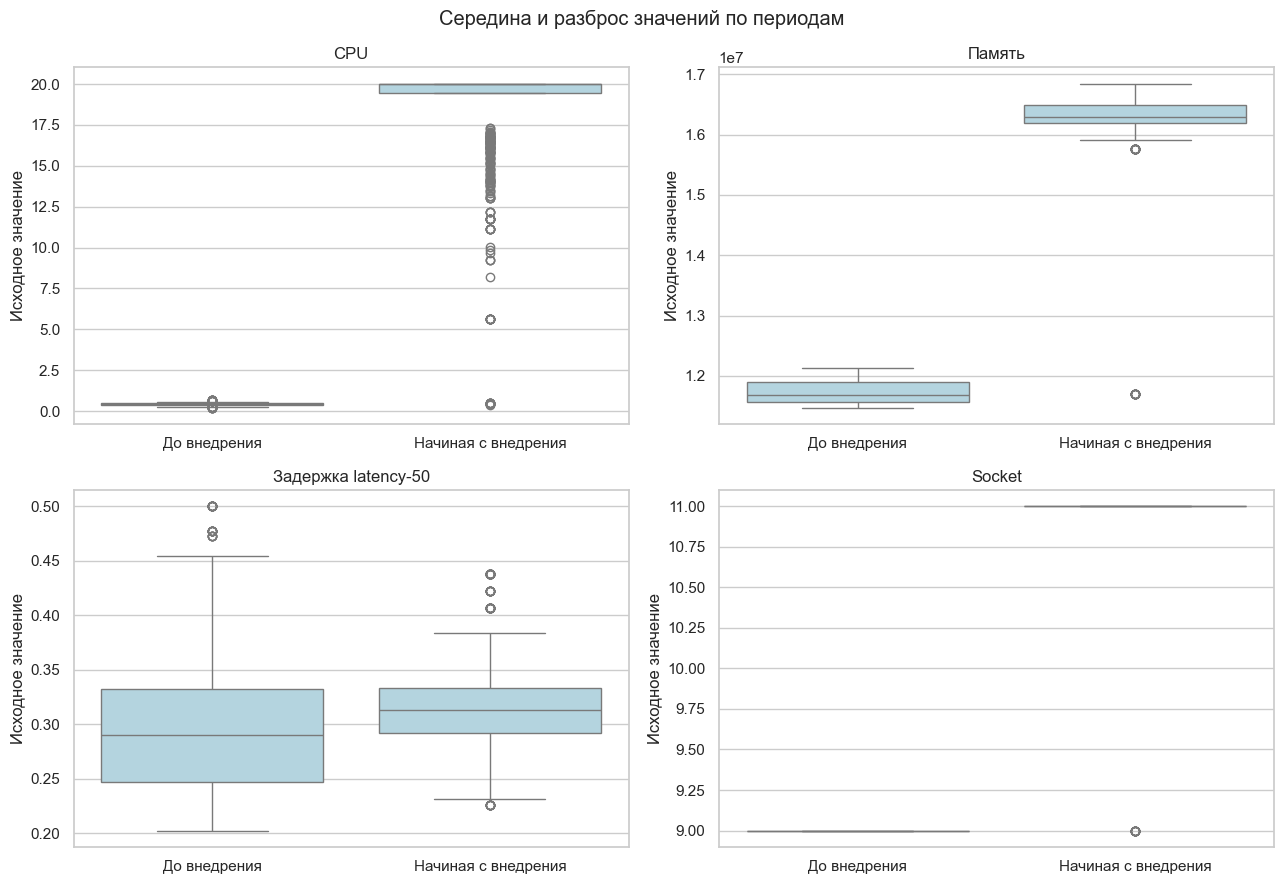

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, metrics):
    sns.boxplot(data=plot_data, x='Период', y=metric, order=period_order,
                color='lightblue', ax=ax)
    ax.set(title=metric_labels[metric], xlabel='', ylabel='Исходное значение')
fig.suptitle('Середина и разброс значений по периодам')
fig.tight_layout()
save_show(fig, '14_rcaeval_boxplot.png')

Положение линии внутри ящика позволяет сравнить медианы. После внедрения у CPU, памяти и socket они выше. Отдельные точки означают необычные значения для своей группы по правилу boxplot; автоматически считать их ошибками или сбоями нельзя.

### 3.6. Countplot по периодам
В исходных метриках нет категорий вроде штата или ухода клиента. Для демонстрации countplot используем известный период измерения. Это подпись, рассчитанная по времени, а не новая целевая переменная для обучения.

Показываем число строк до и после внедрения сбоя.

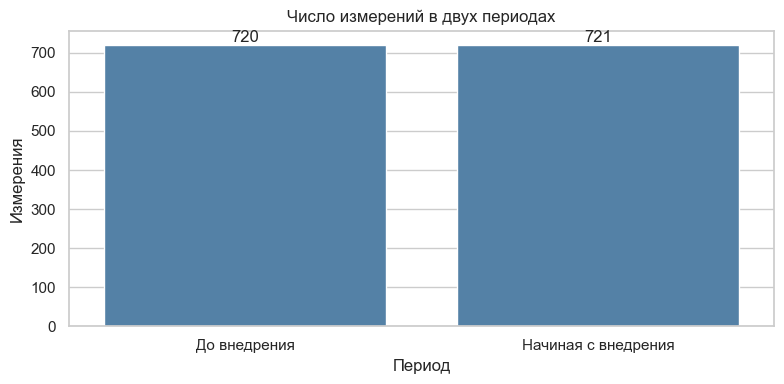

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=plot_data, x='Период', order=period_order, color='steelblue', ax=ax)
ax.set(title='Число измерений в двух периодах', xlabel='Период', ylabel='Измерения')
for container in ax.containers:
    ax.bar_label(container)
fig.tight_layout()
save_show(fig, '15_rcaeval_countplot.png')

Группы почти одинакового размера: до внедрения 720 строк, начиная с него — 721. График сообщает количество записей, а не частоту сбоев системы.

### 3.7. Несколько диаграмм рассеяния
Сравниваем три разные пары. По осям стоят фактические метрики, одна точка соответствует одной строке. Для каждой пары используем только совместно заполненные значения.

Строим три парные проекции с цветом периода.

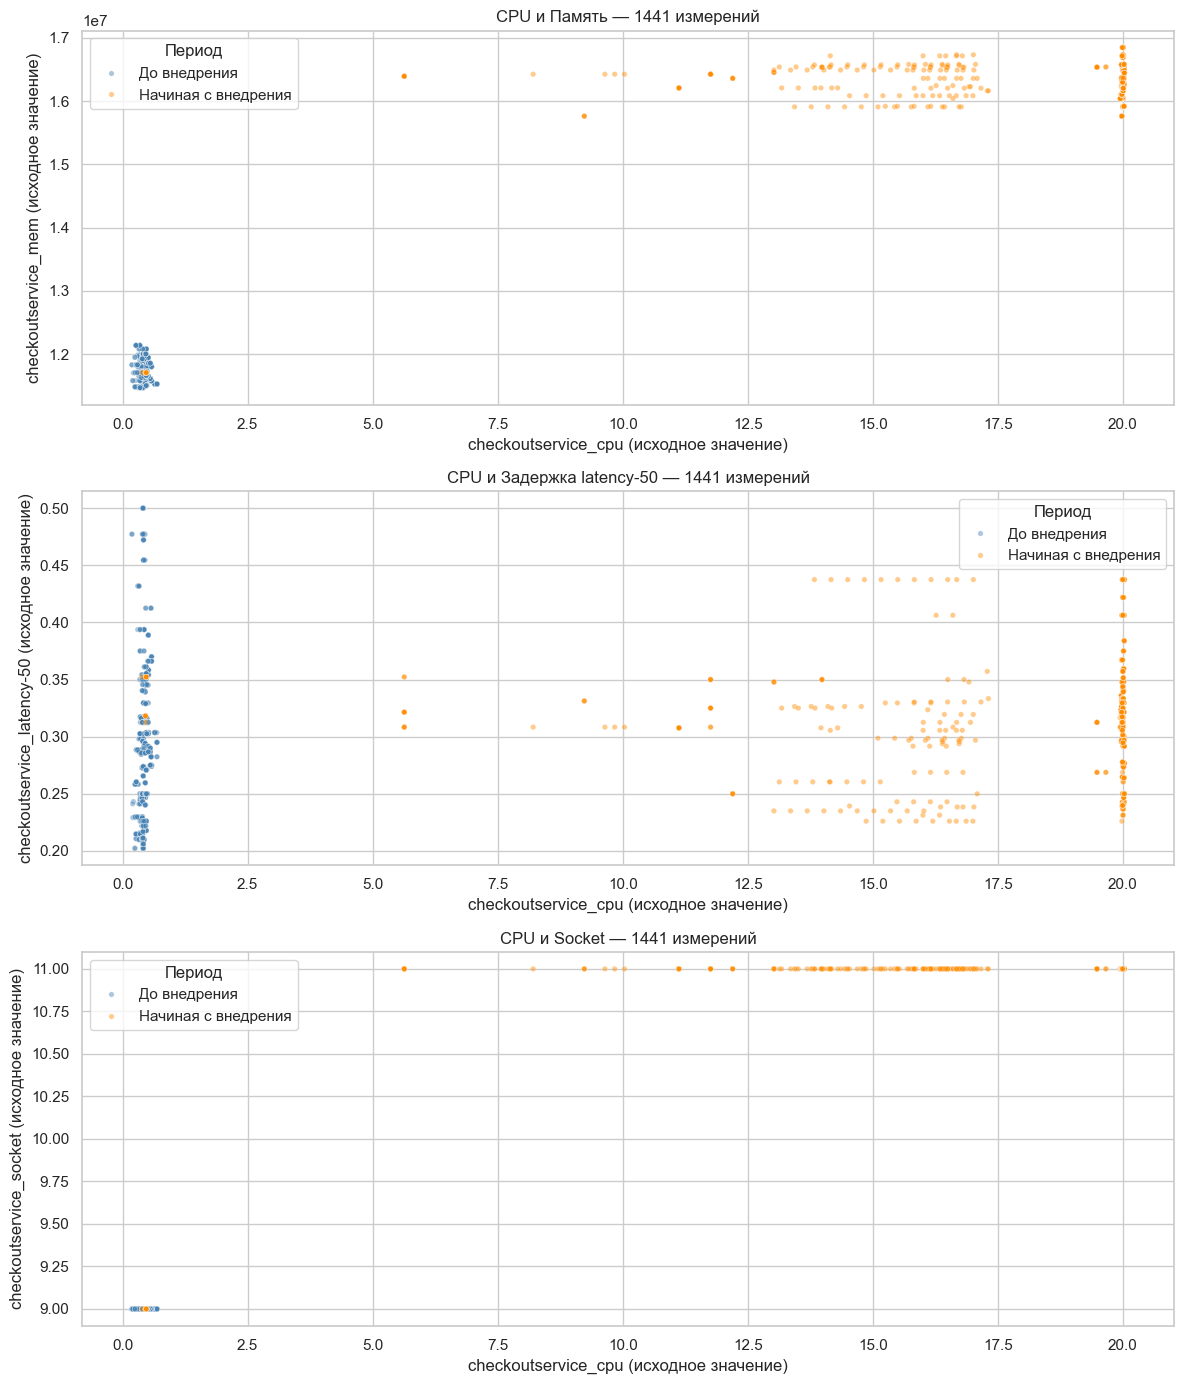

In [35]:
pairs = [(metrics[0], metrics[1]), (metrics[0], metrics[2]), (metrics[0], metrics[3])]
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
for ax, (x, y) in zip(axes, pairs):
    pair = plot_data[[x, y, 'Период']].dropna()
    sns.scatterplot(data=pair, x=x, y=y, hue='Период', hue_order=period_order,
                    palette=colors, s=15, alpha=0.45, ax=ax)
    ax.set(title=f'{metric_labels[x]} и {metric_labels[y]} — {len(pair)} измерений',
           xlabel=x + ' (исходное значение)', ylabel=y + ' (исходное значение)')
fig.tight_layout()
save_show(fig, '16_rcaeval_scatter.png')

Для CPU и памяти группы находятся в разных областях: до внедрения оба показателя ниже, после — выше. Аналогичное разделение видно для CPU и socket. На паре CPU и задержки значения задержки в двух периодах сильнее перемешиваются.

### 3.8. Pairplot
Собираем все пары выбранных показателей на одном рисунке. На диагонали идут гистограммы. Это помогает быстро просмотреть несколько проекций, не выбирая одну заранее.

Строим полную сетку парных графиков.

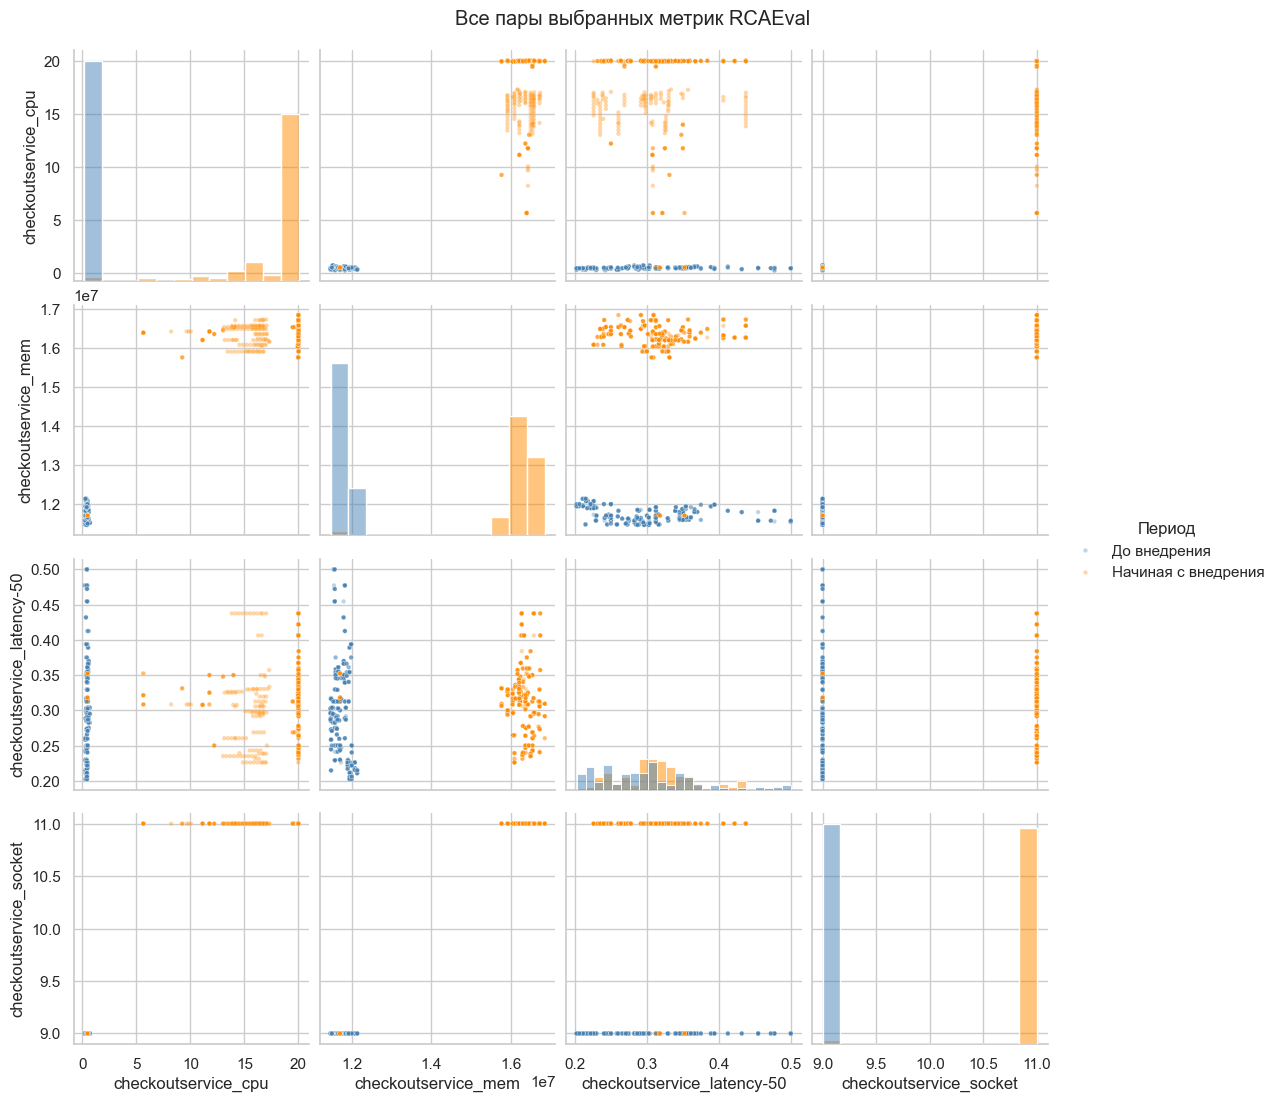

In [36]:
grid = sns.pairplot(plot_data, vars=metrics, hue='Период', hue_order=period_order,
                    palette=colors, diag_kind='hist', height=2.7,
                    plot_kws={'s': 10, 'alpha': 0.35}, diag_kws={'common_norm': False})
grid.figure.suptitle('Все пары выбранных метрик RCAEval', y=1.02)
save_show(grid.figure, '17_rcaeval_pairplot.png')

Pairplot подтверждает разделение периодов по нескольким метрикам. Цветные группы на этих данных отражают время до и после внесения сбоя. Они сами по себе не являются проверенным правилом поиска новых сбоев.

### 3.9. Тепловые карты корреляций
Рассматриваем выбранные показатели за всё время и отдельно в каждом периоде. Это важно: высокий коэффициент за весь период может получиться просто потому, что два показателя одновременно перешли на другой уровень.

Рассчитываем корреляции и число общих измерений каждой пары.

In [37]:
correlations = {'Все измерения': plot_data[metrics].corr()}
for period in period_order:
    correlations[period] = plot_data.loc[plot_data['Период'] == period, metrics].corr()
valid = plot_data[metrics].notna().astype(int)
pair_counts = valid.T @ valid
display(pair_counts.rename(index=metric_labels, columns=metric_labels))
pair_counts.to_csv(REPORT / 'rcaeval_pair_counts.csv')
for name, matrix in correlations.items():
    matrix.to_csv(REPORT / f'rcaeval_corr_{list(correlations).index(name)}.csv')

,CPU,Память,Задержка latency-50,Socket
CPU,1441,1441,1441,1441
Память,1441,1441,1441,1441
Задержка latency-50,1441,1441,1441,1441
Socket,1441,1441,1441,1441


Строим карты за весь период и по двум группам.

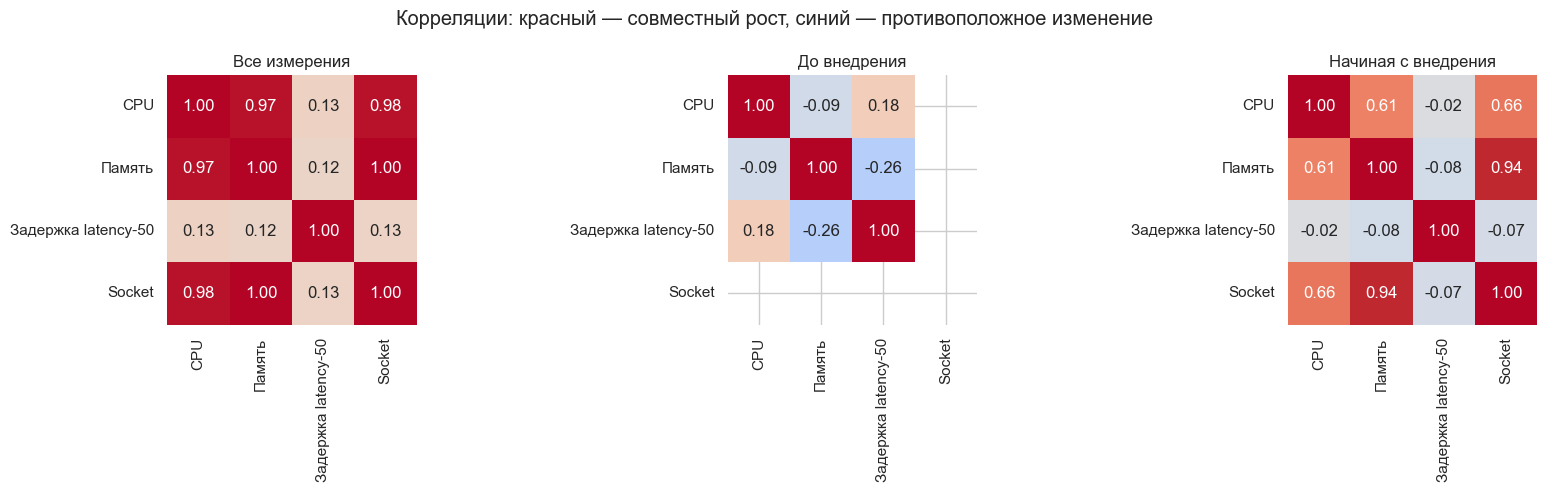

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, matrix) in zip(axes, correlations.items()):
    labeled = matrix.rename(index=metric_labels, columns=metric_labels)
    sns.heatmap(labeled, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                center=0, square=True, ax=ax, cbar=False)
    ax.set_title(name)
fig.suptitle('Корреляции: красный — совместный рост, синий — противоположное изменение')
fig.tight_layout()
save_show(fig, '18_rcaeval_heatmaps.png')

Цветовая шкала одинакова на всех трёх картах: от −1 до 1. Сравниваем коэффициенты, а не только яркость. Если значение в отдельном периоде заметно меньше общего, общая связь могла усилиться из-за смены уровня показателей. Причину изменения по одной корреляции установить нельзя.

Пустая клетка означает, что корреляцию нельзя посчитать, например когда показатель весь период одинаковый. Это не нулевая связь. В периоде до внедрения socket постоянно равен 9.

### 3.10. Накопленные доли значений
Дополнительно используем ECDF. Для значения по горизонтали график показывает, какая доля измерений не превышает это значение. Доля меняется от 0 до 1, поэтому группы можно сравнивать даже при разном числе строк.

Строим ECDF для выбранных показателей.

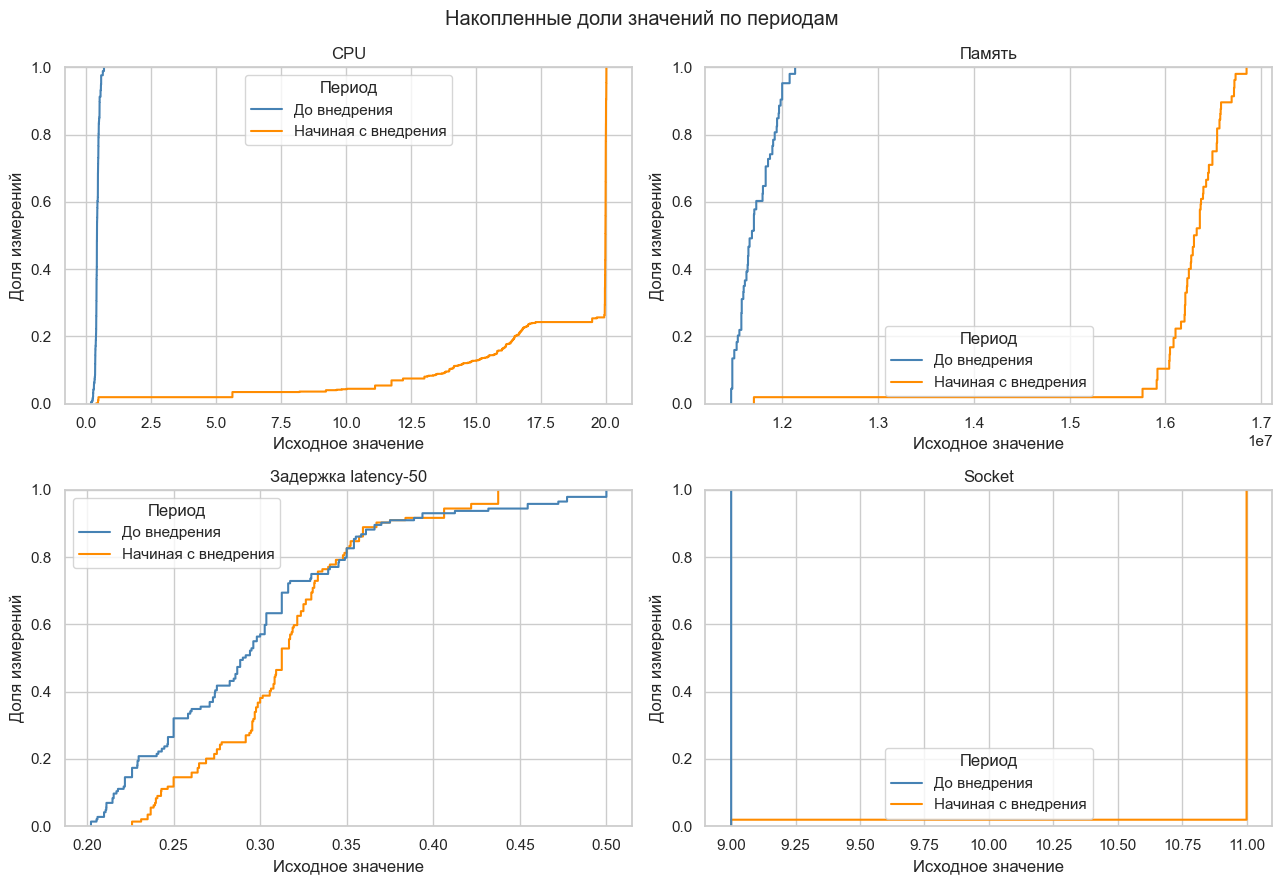

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, metrics):
    sns.ecdfplot(data=plot_data, x=metric, hue='Период', hue_order=period_order,
                 palette=colors, ax=ax)
    ax.set(title=metric_labels[metric], xlabel='Исходное значение', ylabel='Доля измерений')
fig.suptitle('Накопленные доли значений по периодам')
fig.tight_layout()
save_show(fig, '19_rcaeval_ecdf.png')

У CPU и памяти кривые двух периодов сдвинуты относительно друг друга: после внедрения значения в основном выше. У задержки кривые ближе. В отличие от гистограммы здесь не нужно выбирать ширину интервалов.

Формируем простой текст результатов индивидуального задания.

In [40]:
r_all = correlations['Все измерения'].loc[metrics[0], metrics[1]]
r_before = correlations[period_order[0]].loc[metrics[0], metrics[1]]
r_after = correlations[period_order[1]].loc[metrics[0], metrics[1]]
lines = [
    f'Использован прежний сценарий **{case}**: **{len(df)}** строк и **{df.shape[1] - 1}** метрики. '
    'RCAEval прочитан из локальных файлов без скачивания.',
    f'До внедрения **{int(period_counts.iloc[0])}** строк, начиная с внедрения **{int(period_counts.iloc[1])}**. '
    f'В исходной таблице пропущено значений: **{int(df.isna().sum().sum())}**.',
    'Графики показывают, что CPU, память и socket после отметки сбоя стали выше. '
    'Задержка менялась в обоих периодах; не каждый её пик связан со сбоем.',
    f'Для CPU и памяти корреляция за всё время равна **{r_all:.3f}**, '
    f'до внедрения — **{r_before:.3f}**, после — **{r_after:.3f}**. '
    'Эти числа показывают, насколько близко меняются показатели в каждом периоде.',
    'Гистограммы показывают частоты, boxplot — середину и разброс, временные ряды — порядок изменений, '
    'парные графики — сочетания метрик, тепловые карты — их совместное изменение. '
    'Мы изучили один пример, поэтому для проверки выводов нужны и другие сбои.'
]
analysis_text = '\n\n'.join(lines)
display(Markdown(analysis_text))
(REPORT / 'analysis.md').write_text('# Анализ результатов\n\n' + analysis_text, encoding='utf-8')

Использован прежний сценарий **re2ob_checkoutservice_cpu_1**: **1441** строк и **72** метрики. RCAEval прочитан из локальных файлов без скачивания.

До внедрения **720** строк, начиная с внедрения **721**. В исходной таблице пропущено значений: **4**.

Графики показывают, что CPU, память и socket после отметки сбоя стали выше. Задержка менялась в обоих периодах; не каждый её пик связан со сбоем.

Для CPU и памяти корреляция за всё время равна **0.972**, до внедрения — **-0.089**, после — **0.612**. Эти числа показывают, насколько близко меняются показатели в каждом периоде.

Гистограммы показывают частоты, boxplot — середину и разброс, временные ряды — порядок изменений, парные графики — сочетания метрик, тепловые карты — их совместное изменение. Мы изучили один пример, поэтому для проверки выводов нужны и другие сбои.

Сохраняем сведения об использованных файлах и список графиков.

In [41]:
sources = {
    'telecom': {'url': telecom_url, 'sha256': hashlib.sha256(telecom_path.read_bytes()).hexdigest()},
    'rcaeval': selection,
    'local_metrics': str(metrics_path.relative_to(ROOT)),
    'metrics_sha256': hashlib.sha256(metrics_path.read_bytes()).hexdigest()
}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')
print('Сохранённые графики:')
for path in sorted(FIGURES.glob('*.png')):
    print(path.name)

Сохранённые графики:
01_telecom_day_hist.png
02_telecom_all_hist.png
03_telecom_bar_and_hist.png
04_telecom_boxplot.png
05_telecom_state_boxplot.png
06_telecom_countplot.png
07_telecom_charge_hist.png
08_telecom_pairplot.png
09_telecom_pairplot_churn.png
10_telecom_scatter_styles.png
11_telecom_heatmap.png
12_rcaeval_time.png
13_rcaeval_hist.png
14_rcaeval_boxplot.png
15_rcaeval_countplot.png
16_rcaeval_scatter.png
17_rcaeval_pairplot.png
18_rcaeval_heatmaps.png
19_rcaeval_ecdf.png
